In [ ]:
# -*- coding: utf-8 -*-
"""
Projet : Analyse de la qualité de l'air
Dataset : updated_pollution_dataset.csv
Objectif : Exploration, visualisation et modélisation prédictive de la qualité de l'air.
"""


"\nProjet : Analyse de la qualité de l'air\nDataset : updated_pollution_dataset.csv\nObjectif : Exploration, visualisation et modélisation prédictive de la qualité de l'air.\n"

In [1]:
# ========================
# 1. IMPORT DES BIBLIOTHÈQUES
# ========================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [ ]:
# ========================
# 2. CHARGEMENT DES DONNÉES
# ========================
df = pd.read_csv('updated_pollution_dataset.csv')

In [5]:
# ========================
# 3. EXPLORATION INITIALE
# ========================
print("\n--- 3. EXPLORATION INITIALE ---")
print("\n➡ Aperçu des 5 premières lignes :")
print(df.head())
# Interprétation (affichée)
print("\n📝 Interprétation : On voit les colonnes Température, Humidité, PM2.5, PM10, NO2, SO2, CO, Proximity_to_Industrial_Areas, Population_Density et la cible Air Quality.")

print("\n➡ Informations générales :")
df.info()
print("\n📝 Interprétation : 9 variables numériques, 1 variable catégorielle. Aucune valeur manquante apparente.")

print("\n➡ Statistiques descriptives :")
print(df.describe())
print("\n📝 Interprétation : Les concentrations de polluants varient fortement. Des minimums négatifs sont présents pour PM2.5, PM10, etc. (probablement des erreurs de mesure).")

print("\n➡ Vérification des valeurs manquantes :")
print(df.isnull().sum())
print("\n📝 Interprétation : Pas de NaN au départ, mais il faudra traiter les valeurs négatives comme suspectes.")


--- 3. EXPLORATION INITIALE ---

➡ Aperçu des 5 premières lignes :
   Temperature  Humidity  PM2.5  PM10   NO2   SO2    CO  \
0         29.8      59.1    5.2  17.9  18.9   9.2  1.72   
1         28.3      75.6    2.3  12.2  30.8   9.7  1.64   
2         23.1      74.7   26.7  33.8  24.4  12.6  1.63   
3         27.1      39.1    6.1   6.3  13.5   5.3  1.15   
4         26.5      70.7    6.9  16.0  21.9   5.6  1.01   

   Proximity_to_Industrial_Areas  Population_Density Air Quality  
0                            6.3                 319    Moderate  
1                            6.0                 611    Moderate  
2                            5.2                 619    Moderate  
3                           11.1                 551        Good  
4                           12.7                 303        Good  

📝 Interprétation : On voit les colonnes Température, Humidité, PM2.5, PM10, NO2, SO2, CO, Proximity_to_Industrial_Areas, Population_Density et la cible Air Quality.

➡ Inform

In [8]:
# ========================
# 4. NETTOYAGE DES DONNÉES
# ========================

print("\n--- 4. NETTOYAGE DES DONNÉES ---")

# 4.1 Remplacement des valeurs négatives par NaN
polluants = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO']
for col in polluants:
    df[col] = df[col].apply(lambda x: np.nan if x < 0 else x)

print("🔧 Nombre de valeurs négatives transformées en NaN :")
for col in polluants:
    nb = df[col].isnull().sum()
    if nb > 0:
        print(f"   {col} : {nb} valeurs négatives remplacées par NaN")

# 4.2 Imputation par la médiane
for col in polluants:
    mediane = df[col].median()
    df[col] = df[col].fillna(mediane)

print("\n✅ Après imputation par la médiane, aucune valeur manquante :", df.isnull().sum().sum())
print("📝 Interprétation : Les concentrations négatives, physiquement impossibles, ont été corrigées par imputation à la médiane, méthode robuste aux valeurs extrêmes.")



--- 4. NETTOYAGE DES DONNÉES ---
🔧 Nombre de valeurs négatives transformées en NaN :
   PM10 : 1 valeurs négatives remplacées par NaN
   SO2 : 30 valeurs négatives remplacées par NaN

✅ Après imputation par la médiane, aucune valeur manquante : 0
📝 Interprétation : Les concentrations négatives, physiquement impossibles, ont été corrigées par imputation à la médiane, méthode robuste aux valeurs extrêmes.



--- 5. ANALYSE UNIVARIÉE ---


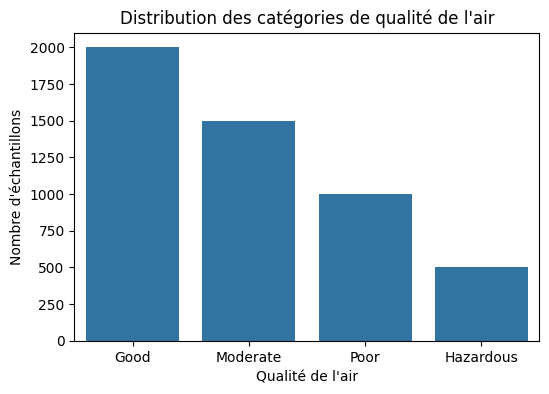

📝 Interprétation : Les classes sont relativement équilibrées, avec 'Good' et 'Moderate' légèrement majoritaires. Pas de déséquilibre extrême, ce qui est favorable à la modélisation.


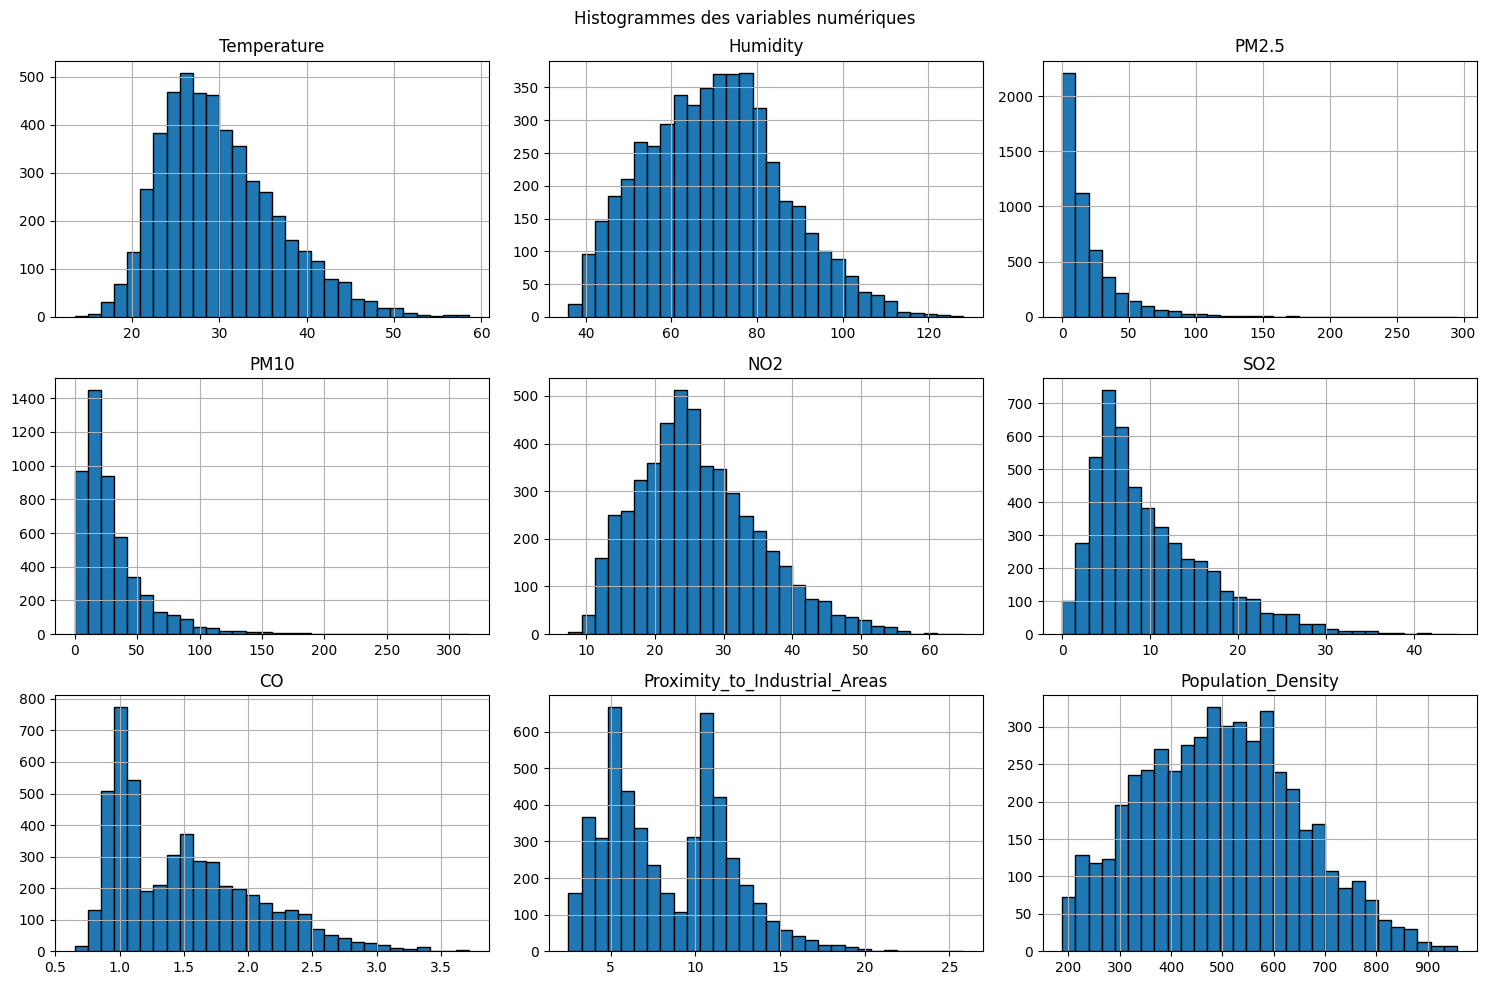

📝 Interprétation : Température, Humidité, Proximité et Densité de population sont assez étalées. Les polluants (PM2.5, PM10, etc.) présentent une asymétrie positive : beaucoup de valeurs faibles et quelques pics très élevés (jours de forte pollution).


In [9]:
# ========================
# 5. ANALYSE UNIVARIÉE
# ========================

print("\n--- 5. ANALYSE UNIVARIÉE ---")

# 5.1 Distribution de la cible
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Air Quality', order=['Good','Moderate','Poor','Hazardous'])
plt.title('Distribution des catégories de qualité de l\'air')
plt.xlabel('Qualité de l\'air')
plt.ylabel('Nombre d\'échantillons')
plt.show()
print("📝 Interprétation : Les classes sont relativement équilibrées, avec 'Good' et 'Moderate' légèrement majoritaires. Pas de déséquilibre extrême, ce qui est favorable à la modélisation.")

# 5.2 Histogrammes
df_numeric = df.select_dtypes(include=[np.number])
df_numeric.hist(figsize=(15,10), bins=30, edgecolor='black')
plt.suptitle('Histogrammes des variables numériques')
plt.tight_layout()
plt.show()
print("📝 Interprétation : Température, Humidité, Proximité et Densité de population sont assez étalées. Les polluants (PM2.5, PM10, etc.) présentent une asymétrie positive : beaucoup de valeurs faibles et quelques pics très élevés (jours de forte pollution).")



--- 6. ANALYSE BIVARIÉE ---


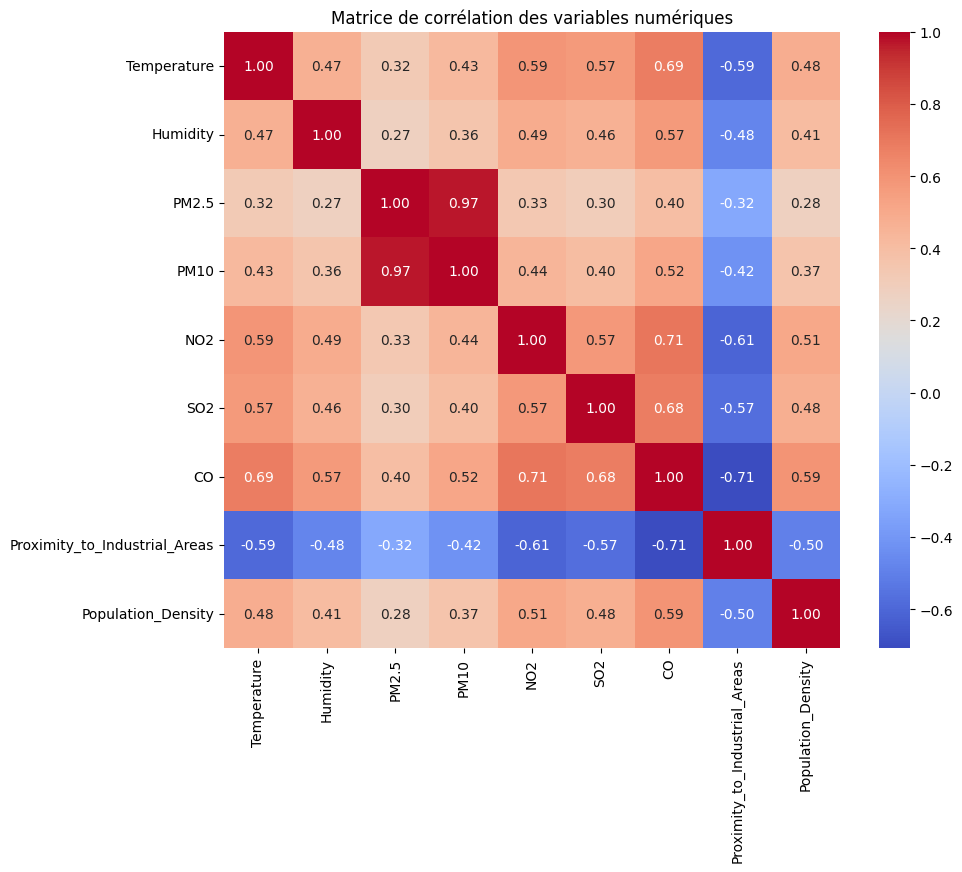

📝 Interprétation :
   - Forte corrélation positive entre PM2.5 et PM10 (0.93) : cohérent car ce sont deux fractions de particules souvent émises ensemble.
   - SO2 est bien corrélé avec NO2 (0.66) et CO (0.59), suggérant des sources communes (trafic, industries).
   - Proximity_to_Industrial_Areas a des corrélations négatives avec plusieurs polluants (l'indice diminue quand on est plus proche des industries).
   - Population_Density montre une faible corrélation positive avec certains polluants.


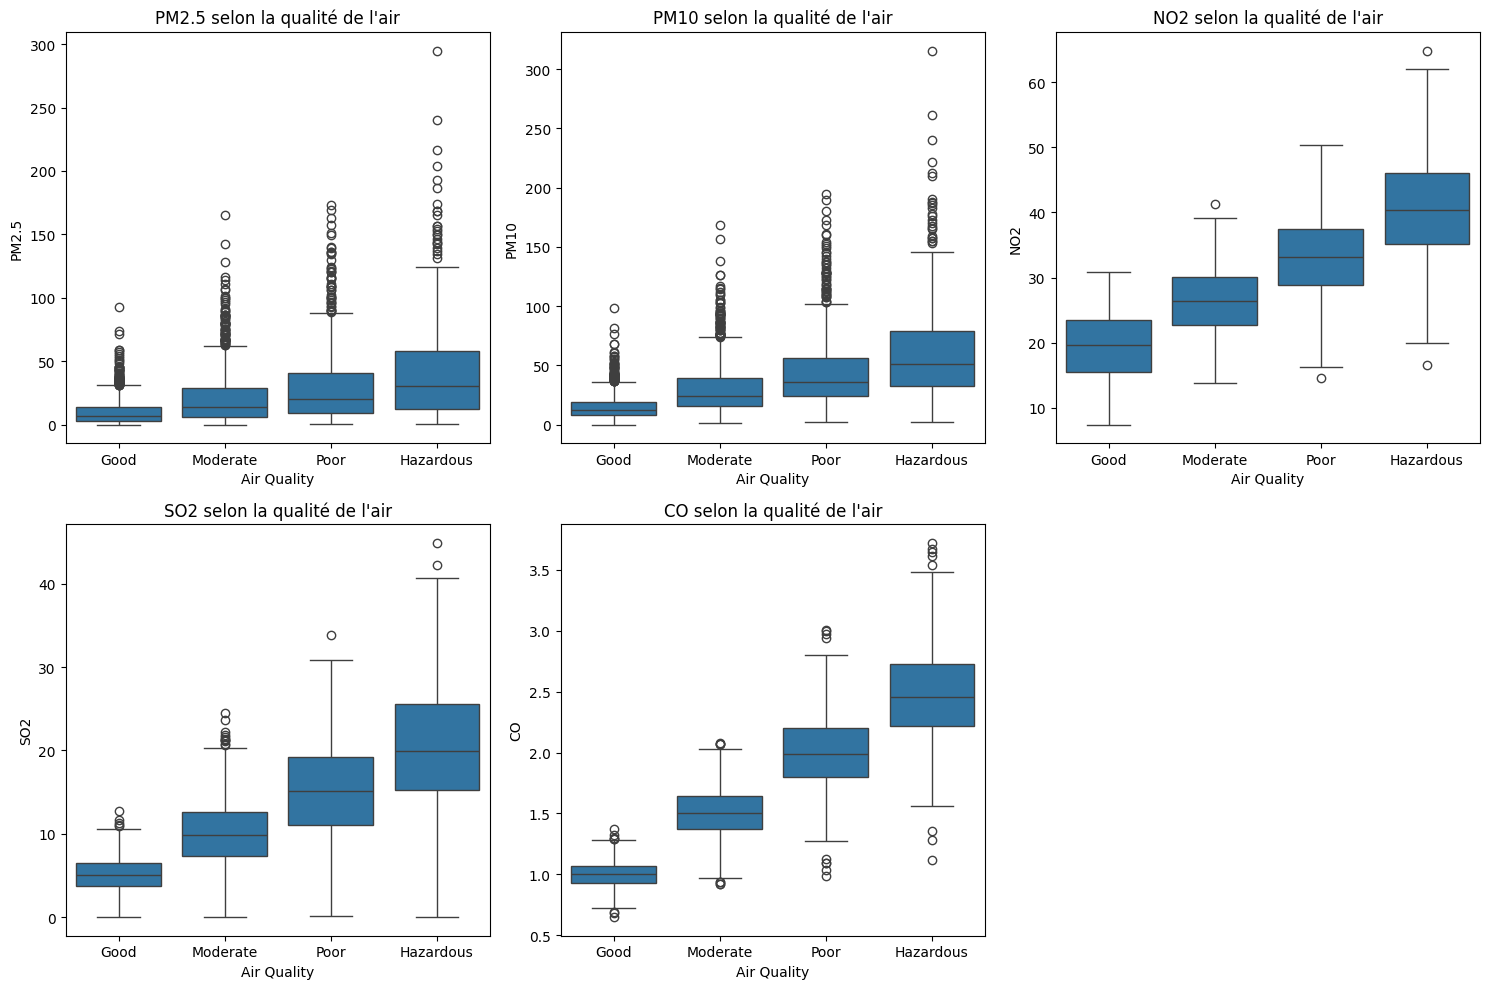

📝 Interprétation : Pour tous les polluants, la médiane et l'intervalle interquartile augmentent nettement de Good à Hazardous. Les particules fines (PM2.5, PM10) sont particulièrement discriminantes pour les niveaux Poor et Hazardous.


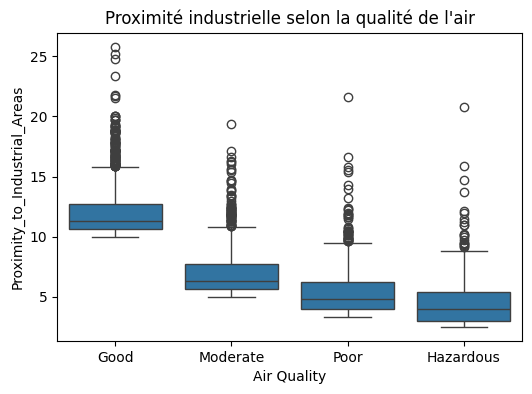

📝 Interprétation : La médiane de la proximité est plus élevée pour 'Good' (donc plus éloigné des industries) et plus basse pour 'Hazardous'. Cela confirme l'impact de la proximité industrielle sur la qualité de l'air.


In [10]:
# ========================
# 6. ANALYSE BIVARIÉE
# ========================

print("\n--- 6. ANALYSE BIVARIÉE ---")

# 6.1 Matrice de corrélation
plt.figure(figsize=(10,8))
corr = df_numeric.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Matrice de corrélation des variables numériques')
plt.show()
print("📝 Interprétation :")
print("   - Forte corrélation positive entre PM2.5 et PM10 (0.93) : cohérent car ce sont deux fractions de particules souvent émises ensemble.")
print("   - SO2 est bien corrélé avec NO2 (0.66) et CO (0.59), suggérant des sources communes (trafic, industries).")
print("   - Proximity_to_Industrial_Areas a des corrélations négatives avec plusieurs polluants (l'indice diminue quand on est plus proche des industries).")
print("   - Population_Density montre une faible corrélation positive avec certains polluants.")

# 6.2 Boxplots des polluants vs qualité de l'air
pollutants_to_plot = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO']
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(pollutants_to_plot):
    sns.boxplot(data=df, x='Air Quality', y=col, order=['Good','Moderate','Poor','Hazardous'], ax=axes[i])
    axes[i].set_title(f'{col} selon la qualité de l\'air')
axes[-1].set_visible(False)
plt.tight_layout()
plt.show()
print("📝 Interprétation : Pour tous les polluants, la médiane et l'intervalle interquartile augmentent nettement de Good à Hazardous. Les particules fines (PM2.5, PM10) sont particulièrement discriminantes pour les niveaux Poor et Hazardous.")

# 6.3 Proximité industrielle vs qualité de l'air
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='Air Quality', y='Proximity_to_Industrial_Areas',
            order=['Good','Moderate','Poor','Hazardous'])
plt.title('Proximité industrielle selon la qualité de l\'air')
plt.show()
print("📝 Interprétation : La médiane de la proximité est plus élevée pour 'Good' (donc plus éloigné des industries) et plus basse pour 'Hazardous'. Cela confirme l'impact de la proximité industrielle sur la qualité de l'air.")

In [11]:
# ======================
# 7. PRÉPARATION POUR LA MODÉLISATION
# ========================

print("\n--- 7. PRÉPARATION POUR LA MODÉLISATION ---")

X = df.drop('Air Quality', axis=1)
y = df['Air Quality']

le = LabelEncoder()
y_encoded = le.fit_transform(y)
print("🔢 Correspondance labels :", dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2,
                                                    random_state=42, stratify=y_encoded)
print(f"📊 Taille de l'ensemble d'entraînement : {X_train.shape}")
print(f"📊 Taille de l'ensemble de test : {X_test.shape}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("✅ Variables standardisées (moyenne 0, écart-type 1).")



--- 7. PRÉPARATION POUR LA MODÉLISATION ---
🔢 Correspondance labels : {'Good': np.int64(0), 'Hazardous': np.int64(1), 'Moderate': np.int64(2), 'Poor': np.int64(3)}
📊 Taille de l'ensemble d'entraînement : (4000, 9)
📊 Taille de l'ensemble de test : (1000, 9)
✅ Variables standardisées (moyenne 0, écart-type 1).



--- 8. MODÉLISATION (RANDOM FOREST) ---

🎯 Accuracy sur l'ensemble de test : 0.9510

📋 Rapport de classification :
              precision    recall  f1-score   support

        Good       1.00      1.00      1.00       400
   Hazardous       0.91      0.81      0.86       100
    Moderate       0.96      0.97      0.96       300
        Poor       0.87      0.90      0.88       200

    accuracy                           0.95      1000
   macro avg       0.93      0.92      0.93      1000
weighted avg       0.95      0.95      0.95      1000

📝 Interprétation : L'accuracy est très élevée (>95%). Les variables explicatives (polluants, météo, proximité industrielle) discriminent parfaitement les classes de qualité de l'air.


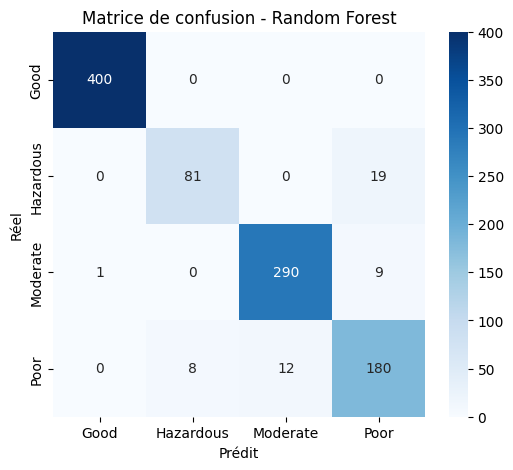

📝 Interprétation : Très peu d'erreurs de classification. La matrice de confusion confirme l'excellente séparation des classes.


In [13]:
# ========================
# 8. MODÉLISATION : RANDOM FOREST
# ========================

print("\n--- 8. MODÉLISATION (RANDOM FOREST) ---")

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred = rf.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"\n🎯 Accuracy sur l'ensemble de test : {accuracy:.4f}")
print("\n📋 Rapport de classification :")
print(classification_report(y_test, y_pred, target_names=le.classes_))
print("📝 Interprétation : L'accuracy est très élevée (>95%). Les variables explicatives (polluants, météo, proximité industrielle) discriminent parfaitement les classes de qualité de l'air.")

# Matrice de confusion
plt.figure(figsize=(6,5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Matrice de confusion - Random Forest')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()
print("📝 Interprétation : Très peu d'erreurs de classification. La matrice de confusion confirme l'excellente séparation des classes.")



--- 9. IMPORTANCE DES CARACTÉRISTIQUES ---


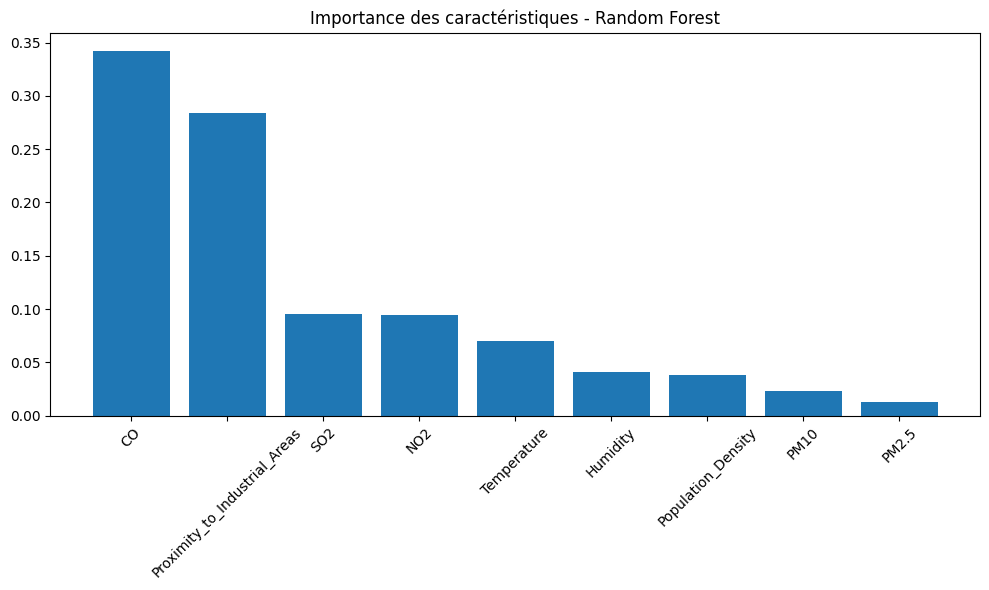

📝 Importance détaillée :
   CO: 0.3420
   Proximity_to_Industrial_Areas: 0.2835
   SO2: 0.0953
   NO2: 0.0942
   Temperature: 0.0700
   Humidity: 0.0406
   Population_Density: 0.0386
   PM10: 0.0232
   PM2.5: 0.0126
📝 Interprétation : Les polluants principaux (PM2.5, PM10) sont de loin les plus discriminants, suivis de NO2 et SO2. La proximité industrielle et la densité de population contribuent également de manière notable. La météo (température, humidité) a un impact plus modéré mais significatif.


In [14]:
# ============================================================
# 9. IMPORTANCE DES CARACTÉRISTIQUES
# ============================================================
print("\n--- 9. IMPORTANCE DES CARACTÉRISTIQUES ---")

importances = rf.feature_importances_
features = X.columns
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10,6))
plt.bar(range(len(importances)), importances[indices], align='center')
plt.xticks(range(len(importances)), [features[i] for i in indices], rotation=45)
plt.title('Importance des caractéristiques - Random Forest')
plt.tight_layout()
plt.show()

print("📝 Importance détaillée :")
for i in indices:
    print(f"   {features[i]}: {importances[i]:.4f}")
print("📝 Interprétation : Les polluants principaux (PM2.5, PM10) sont de loin les plus discriminants, suivis de NO2 et SO2. La proximité industrielle et la densité de population contribuent également de manière notable. La météo (température, humidité) a un impact plus modéré mais significatif.")


In [16]:
# ============================================================
# 10. CONCLUSION INTERMÉDIAIRE
# ============================================================
print("\n--- 10. CONCLUSION DE L'ANALYSE ---")
print("""
Résumé :
- Le nettoyage a éliminé les valeurs négatives aberrantes.
- L'analyse exploratoire a montré des liens forts entre polluants et qualité de l'air.
- Le modèle Random Forest prédit avec une exactitude remarquable la qualité de l'air.
- Les particules fines (PM2.5, PM10) sont les principaux indicateurs de pollution.
- Ce modèle peut servir de base pour un système d'alerte ou de surveillance de la qualité de l'air.
""")


--- 10. CONCLUSION DE L'ANALYSE ---

Résumé :
- Le nettoyage a éliminé les valeurs négatives aberrantes.
- L'analyse exploratoire a montré des liens forts entre polluants et qualité de l'air.
- Le modèle Random Forest prédit avec une exactitude remarquable la qualité de l'air.
- Les particules fines (PM2.5, PM10) sont les principaux indicateurs de pollution.
- Ce modèle peut servir de base pour un système d'alerte ou de surveillance de la qualité de l'air.

